In [ ]:

import argparse
import matplotlib.pyplot as plt
import os
import pandas as pd
import seaborn as sns
from skimage import color

from colorizers import *

In [ ]:
parser = argparse.ArgumentParser()
parser.add_argument('-i','--img_path', type=str, default='imgs/ansel_adams3.jpg')
parser.add_argument('--use_gpu', action='store_true', help='whether to use GPU')
parser.add_argument('-o','--save_prefix', type=str, default='saved', help='will save into this file with {eccv16.png, siggraph17.png} suffixes')

opt = parser.parse_known_args()[0]

In [ ]:

# load colorizers
#from colorizers import attention26


colorizer_eccv16 = eccv16(pretrained=True).eval()
# TODO can I load pretrained weights for attention26 if I added a layer?
colorizer_attention26 = attention26(pretrained=True).eval()
if(opt.use_gpu):
	colorizer_eccv16.cuda()
	colorizer_attention26.cuda()

# 2. Freeze early layers (adjust this list to match your definition of "early")
modules_to_freeze = [colorizer_attention26.model1, colorizer_attention26.model2, colorizer_attention26.model3, colorizer_attention26.model4]

for module in modules_to_freeze:
    for param in module.parameters():
        param.requires_grad = False
# BatchNorm stats: If you freeze model1–model4, their BN layers will still update during train(). 
# To fully freeze them, call module.eval() on those blocks during training, 
# or use torch.nn.SyncBatchNorm.convert_sync_batchnorm() with track_running_stats=False

# default size to process images is 256x256
# grab L channel in both original ("orig") and resized ("rs") resolutiMHASpatialAttention(in_channels=512, num_heads=8)ons
img = load_img(opt.img_path)
(tens_l_orig, tens_l_rs) = preprocess_img(img, HW=(256,256))
if(opt.use_gpu):
	tens_l_rs = tens_l_rs.cuda()
      
print(f'Notebook tens_l_rs shape: {tens_l_rs.shape}')

# colorizer outputs 256x256 ab map
# resize and concatenate to original L channel
img_bw = postprocess_tens(tens_l_orig, torch.cat((0*tens_l_orig,0*tens_l_orig),dim=1))
out_img_eccv16 = postprocess_tens(tens_l_orig, colorizer_eccv16(tens_l_rs).cpu())
out_img_attention26 = postprocess_tens(tens_l_orig, colorizer_attention26(tens_l_rs).cpu()) #colorizer_attention26(tens_l_rs).cpu() this output has a different shape than eccv

# plt.imsave('%s_eccv16.png'%opt.save_prefix, out_img_eccv16)
# plt.imsave('%s_attention26.png'%opt.save_prefix, out_img_attention26)

plt.figure(figsize=(12,8))
plt.subplot(2,2,1)
plt.imshow(img)
plt.title('Original')
plt.axis('off')

plt.subplot(2,2,2)
plt.imshow(img_bw)
plt.title('Input')
plt.axis('off')

plt.subplot(2,2,3)
plt.imshow(out_img_eccv16)
plt.title('Output (ECCV 16)')
plt.axis('off')

plt.subplot(2,2,4)
plt.imshow(out_img_attention26)
plt.title('Output (ATTENTION 26)')
plt.axis('off')
plt.show()


Notebook tens_l_rs shape: torch.Size([1, 1, 256, 256])
tens_orig_l shape: torch.Size([1, 1, 675, 900])
out_ab shape: torch.Size([1, 2, 675, 900])
out_lab_orig shape: torch.Size([1, 3, 675, 900])
 
ECCV conv7_3 shape: torch.Size([1, 512, 32, 32])
tens_orig_l shape: torch.Size([1, 1, 675, 900])
out_ab shape: torch.Size([1, 2, 256, 256])
resize called
out_lab_orig shape: torch.Size([1, 3, 675, 900])
 


/home/steinfath2@top.gwdg.de/colorization-is-all-you-need/colorizers/util.py:55: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 367 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))


conv6_3 shape: torch.Size([1, 512, 32, 32])
conv7_3 shape: torch.Size([1, 512, 32, 32])
Input shape to MHASpatialAttention: torch.Size([1, 512, 32, 32])


RuntimeError: Given normalized_shape=[512], expected input with shape [*, 512], but got input of size[1, 512, 32, 32]

In [ ]:
colorizer_attention26.model7 #.shape

Sequential(
  (0): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU(inplace=True)
  (4): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): ReLU(inplace=True)
  (6): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
)

In [ ]:
tens_l_rs.shape

torch.Size([1, 1, 256, 256])

In [ ]:
break

In [ ]:
# # load colorizers
# colorizer_eccv16 = eccv16(pretrained=True).eval()
# colorizer_siggraph17 = siggraph17(pretrained=True).eval()
# if(opt.use_gpu):
# 	colorizer_eccv16.cuda()
# 	colorizer_siggraph17.cuda()

# # default size to process images is 256x256
# # grab L channel in both original ("orig") and resized ("rs") resolutions
# img_path = 'imgs/Avatar-15th-Anniversary.jpg' #'imgs/ansel_adams2.jpg'
# # img_path = 'imgs/ILSVRC2012_val_00046834.JPEG'
# img = load_img(img_path)
# (tens_l_orig, tens_l_rs) = preprocess_img(img, HW=(256,256))
# if(opt.use_gpu):
# 	tens_l_rs = tens_l_rs.cuda()

# # colorizer outputs 256x256 ab map
# # resize and concatenate to original L channel
# img_bw = postprocess_tens(tens_l_orig, torch.cat((0*tens_l_orig,0*tens_l_orig),dim=1))
# out_img_eccv16 = postprocess_tens(tens_l_orig, colorizer_eccv16(tens_l_rs).cpu())
# out_img_siggraph17 = postprocess_tens(tens_l_orig, colorizer_siggraph17(tens_l_rs).cpu())


In [ ]:
plt.imsave('%s_eccv16.png'%opt.save_prefix, out_img_eccv16)
plt.imsave('%s_siggraph17.png'%opt.save_prefix, out_img_siggraph17)

plt.figure(figsize=(12,8))
plt.subplot(2,2,1)
plt.imshow(img)
plt.title('Original')
plt.axis('off')

plt.subplot(2,2,2)
plt.imshow(img_bw)
plt.title('Input')
plt.axis('off')

plt.subplot(2,2,3)
plt.imshow(out_img_eccv16)
plt.title('Output (ECCV 16)')
plt.axis('off')

plt.subplot(2,2,4)
plt.imshow(out_img_siggraph17)
plt.title('Output (SIGGRAPH 17)')
plt.axis('off')
plt.show()

NameError: name 'out_img_eccv16' is not defined

In [ ]:
import torch
import torch.nn as nn

# 1. Load model & pretrained weights
model = eccv16(pretrained=True)

# 2. Freeze early layers (adjust this list to match your definition of "early")
modules_to_freeze = [model.model1, model.model2, model.model3, model.model4]

for module in modules_to_freeze:
    for param in module.parameters():
        param.requires_grad = False

# 3. Verify freezing worked
print("\n=== Trainable Parameters ===")
for name, param in model.named_parameters():
    if param.requires_grad:
        print(f"✅ {name}")
        
print("\n=== Frozen Parameters ===")
for name, param in model.named_parameters():
    if not param.requires_grad:
        print(f"🔒 {name}")

# 4. Setup optimizer (CRITICAL: only pass trainable parameters)
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()), 
    lr=1e-4
)


=== Trainable Parameters ===
✅ model5.0.weight
✅ model5.0.bias
✅ model5.2.weight
✅ model5.2.bias
✅ model5.4.weight
✅ model5.4.bias
✅ model5.6.weight
✅ model5.6.bias
✅ model6.0.weight
✅ model6.0.bias
✅ model6.2.weight
✅ model6.2.bias
✅ model6.4.weight
✅ model6.4.bias
✅ model6.6.weight
✅ model6.6.bias
✅ model7.0.weight
✅ model7.0.bias
✅ model7.2.weight
✅ model7.2.bias
✅ model7.4.weight
✅ model7.4.bias
✅ model7.6.weight
✅ model7.6.bias
✅ model8.0.weight
✅ model8.0.bias
✅ model8.2.weight
✅ model8.2.bias
✅ model8.4.weight
✅ model8.4.bias
✅ model8.6.weight
✅ model8.6.bias
✅ model_out.weight

=== Frozen Parameters ===
🔒 model1.0.weight
🔒 model1.0.bias
🔒 model1.2.weight
🔒 model1.2.bias
🔒 model1.4.weight
🔒 model1.4.bias
🔒 model2.0.weight
🔒 model2.0.bias
🔒 model2.2.weight
🔒 model2.2.bias
🔒 model2.4.weight
🔒 model2.4.bias
🔒 model3.0.weight
🔒 model3.0.bias
🔒 model3.2.weight
🔒 model3.2.bias
🔒 model3.4.weight
🔒 model3.4.bias
🔒 model3.6.weight
🔒 model3.6.bias
🔒 model4.0.weight
🔒 model4.0.bias
🔒 mode

In [ ]:
# hsv: hue saturation value
# mse on a and b channel
# we have a saturation problem
# introducing GAN generative adversial network 

In [ ]:
from sklearn.metrics import mean_squared_error


def get_hsv(image):
    """Calculates the mean saturation of an image in HSV color space."""
    # Convert RGB to HSV
    hsv_image = color.rgb2hsv(image)
    # Extract the saturation channel
    saturation_channel = hsv_image[:, :, 1]
    # Return the mean saturation
    return np.mean(saturation_channel)


def get_color_mse(img_orig, img_colorized):
    """Calculates the mean squared error (MSE) between the a* and b* channels of two images in LAB color space."""
    # Convert images to LAB color space
    lab_orig = color.rgb2lab(img_orig)
    lab_eccv = color.rgb2lab(img_colorized)
    
    # Extract a* and b* channels
    ab_orig = lab_orig[:, :, 1:3]
    ab_eccv = lab_eccv[:, :, 1:3]
    
    # Calculate MSE for a* and b* channels
    mse_a = mean_squared_error(ab_orig[:, :, 0], ab_eccv[:, :, 0])
    mse_b = mean_squared_error(ab_orig[:, :, 1], ab_eccv[:, :, 1])
    
    return mse_a, mse_b


def get_vibrancy_score(img):
    """Lower = less vibrant/more muted"""
    img_lab = color.rgb2lab(img)
    a, b = img_lab[:,:,1], img_lab[:,:,2]
    saturation = np.sqrt(a**2 + b**2)
    return np.mean(saturation)  # Higher = more vibrant


def get_yellow_tint_score(img):
    """Higher = more yellow/sepia tint"""
    img_lab = color.rgb2lab(img)
    b_channel = img_lab[:,:,2]
    return np.mean(b_channel)  # or np.median(b_channel)

In [ ]:
# load flowers
# predict on flowers
# plot confusion for red and blue
results = {'data_type': [], 'class': [], 'img_name': [], 'saturation': [], 'yellow_tint_score': [],'which_img':[], 'hsv':[], 'a_mse':[], 'b_mse':[]} #, 'pixel_count': []}
data_directory = '/home/steinfath2@top.gwdg.de/colorization/'
for itype in ['flowers','landscape']:
    for iclass in os.walk(f'{data_directory}{itype}/'):
        print(iclass[0])
        for iimg_name in iclass[2][::50]:
            img_path = os.path.join(iclass[0], iimg_name)
            img = load_img(img_path)
            (tens_l_orig, tens_l_rs) = preprocess_img(img, HW=(256,256))
            if(opt.use_gpu):
                tens_l_rs = tens_l_rs.cuda()
            
            out_img_eccv16 = postprocess_tens(tens_l_orig, colorizer_eccv16(tens_l_rs).cpu())
            # out_img_siggraph17 = postprocess_tens(tens_l_orig, colorizer_siggraph17(tens_l_rs).cpu())

            
            #metrics = evaluate_red_blue_performance(img, out_img_eccv16, saturation_threshold=10)
            for jimg, iimg_type in zip([img, out_img_eccv16], ['original', 'eccv16']):
                results['data_type'].append(itype)
                results['class'].append(iclass[0].split('/')[-1])
                results['img_name'].append(iimg_name)
                #results['color'].append(icolor)
                results['saturation'].append(get_vibrancy_score((jimg)))
                results['yellow_tint_score'].append(get_yellow_tint_score((jimg)))
                results['which_img'].append(iimg_type)
                results['hsv'].append(get_hsv((jimg)))
                mse_a, mse_b = get_color_mse(img, jimg)
                results['a_mse'].append(mse_a)
                results['b_mse'].append(mse_b)

            
            # for color, data in metrics.items():
            #     print(f"--- {color} Target Regions ---")
            #     print(f"Evaluated Pixels: {data['pixel_count']}")
            #     print(f"Mean Perceptual Distance (Delta E): {data['mean_delta_E']:.2f}")
            #     print(f"Mean Hue Angular Error: {data['mean_angular_error_deg']:.2f}°")+

            # for icolor in metrics.keys():
            #     results['data_type'].append(itype)
            #     results['class'].append(iclass[0].split('/')[-1])
            #     results['img_name'].append(iimg)
            #     results['color'].append(icolor)
                #results['mean_delta_E'].append(metrics[icolor]['mean_delta_E'])
                #results['mean_angular_error_deg'].append(metrics[icolor]['mean_angular_error_deg'])
                #results['pixel_count'].append(metrics[icolor]['pixel_count'])


/home/steinfath2@top.gwdg.de/colorization/flowers/
/home/steinfath2@top.gwdg.de/colorization/flowers/bellflower


/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 3 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 1 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 6 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 44 negative Z values that hav

/home/steinfath2@top.gwdg.de/colorization/flowers/lotus


/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 21 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 2 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 1 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 313 negative Z values that h

/home/steinfath2@top.gwdg.de/colorization/flowers/sunflower


/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 6 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 20 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 10 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 60 negative Z values that h

/home/steinfath2@top.gwdg.de/colorization/flowers/tulip


/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 269 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 777 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 19 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 196 negative Z values th

/home/steinfath2@top.gwdg.de/colorization/flowers/daisy


/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 101 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 39 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 20 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 76 negative Z values that

/home/steinfath2@top.gwdg.de/colorization/flowers/dandelion


/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 185 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 1 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 6 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 16 negative Z values that h

/home/steinfath2@top.gwdg.de/colorization/flowers/rose


/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 5 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 224 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 3 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 801 negative Z values that 

/home/steinfath2@top.gwdg.de/colorization/landscape/
/home/steinfath2@top.gwdg.de/colorization/landscape/Forest


/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 1 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 3 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 8 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 4 negative Z values that have

/home/steinfath2@top.gwdg.de/colorization/landscape/Mountain


/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 8 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 1 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 1 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 23 negative Z values that hav

/home/steinfath2@top.gwdg.de/colorization/landscape/Desert


/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 77 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 1 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 2 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 23 negative Z values that ha

/home/steinfath2@top.gwdg.de/colorization/landscape/Glacier


/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 1 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 4 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 1 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 2 negative Z values that have

/home/steinfath2@top.gwdg.de/colorization/landscape/Coast


/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 17 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 2 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 16 negative Z values that have been clipped to zero
  return color.lab2rgb(out_lab_orig.data.cpu().numpy()[0,...].transpose((1,2,0)))
/home/steinfath2@top.gwdg.de/colorization/colorizers/util.py:47: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 57 negative Z values that h

In [ ]:
results_df = pd.DataFrame(results)

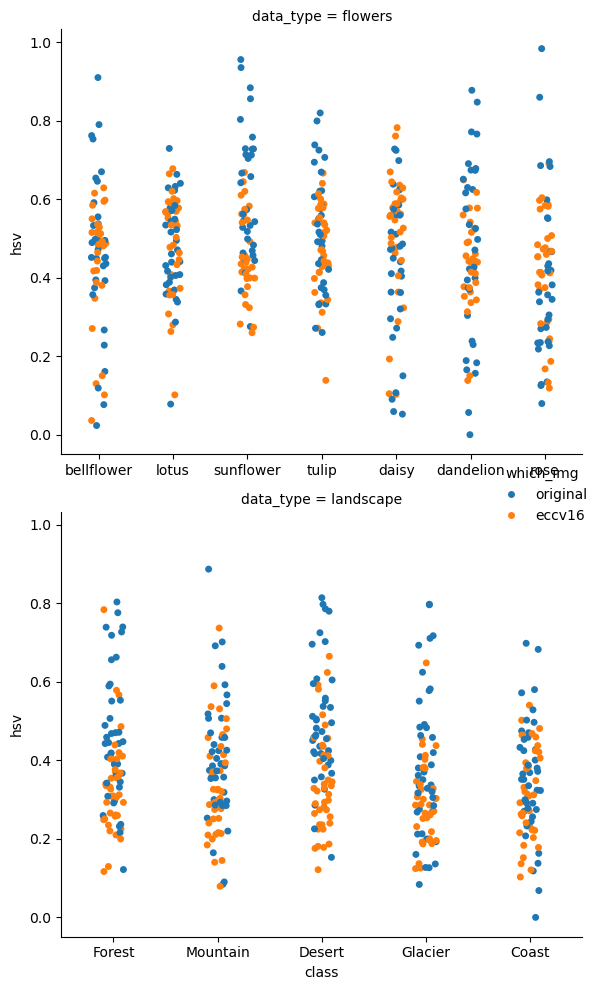

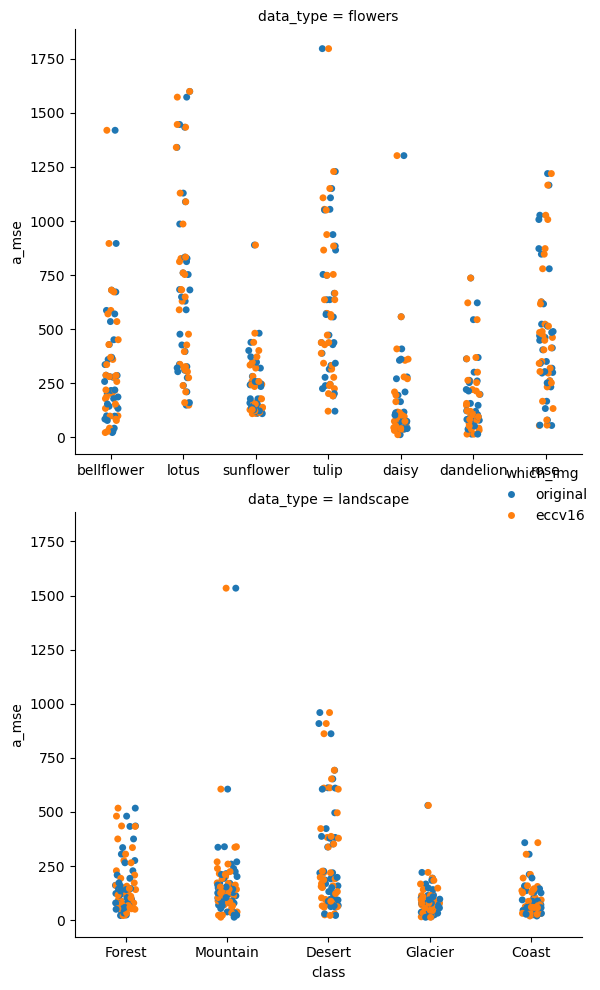

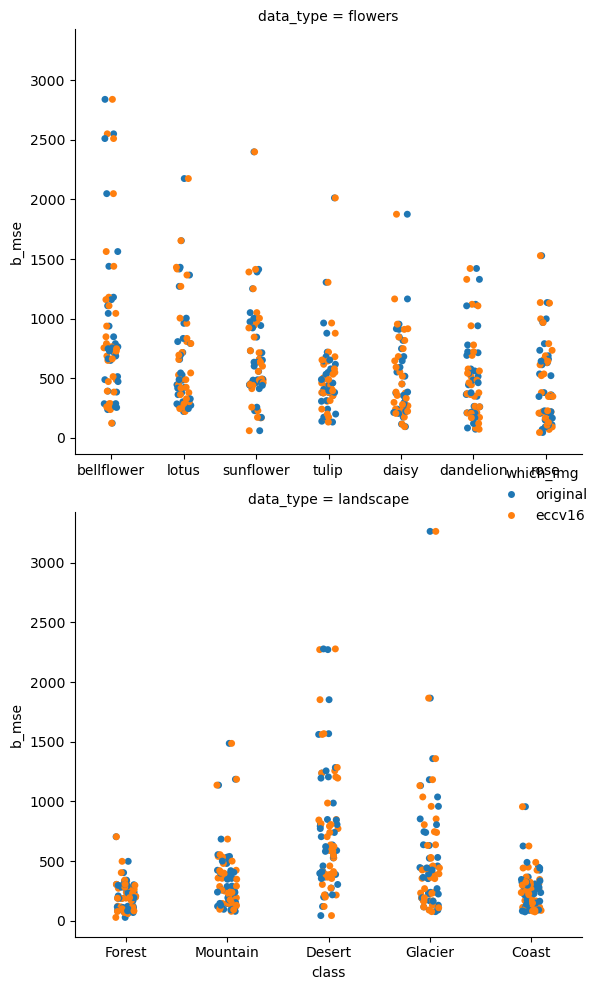

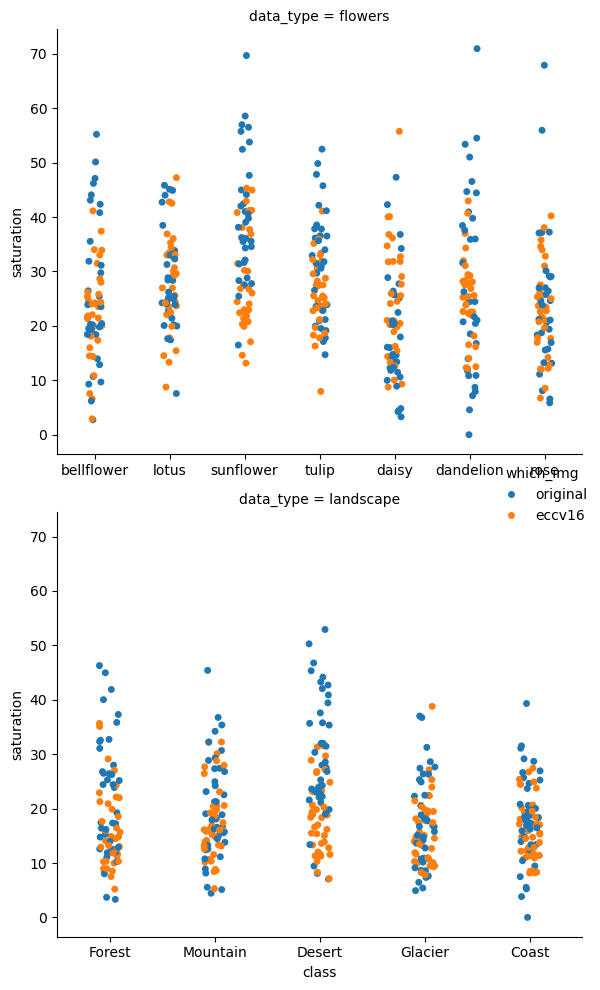

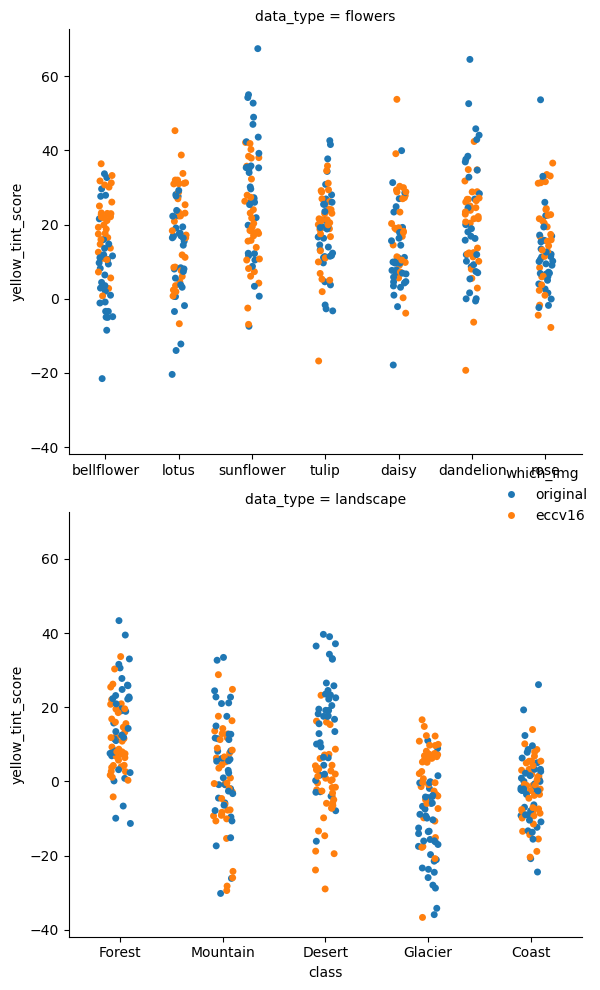

In [ ]:
g = sns.catplot(y='hsv',x="class",hue='which_img',row='data_type',
              data=results_df,sharex=False,kind="strip")
plt.tight_layout()

g = sns.catplot(y='a_mse',x="class",hue='which_img',row='data_type',
              data=results_df,sharex=False,kind="strip")
plt.tight_layout()

g = sns.catplot(y='b_mse',x="class",hue='which_img',row='data_type',
              data=results_df,sharex=False,kind="strip")
plt.tight_layout()

g = sns.catplot(y='saturation',x="class",hue='which_img',row='data_type',
              data=results_df,sharex=False,kind="strip")
plt.tight_layout()

g = sns.catplot(y='yellow_tint_score',x="class",hue='which_img',row='data_type',
              data=results_df,sharex=False,kind="strip")
plt.tight_layout()

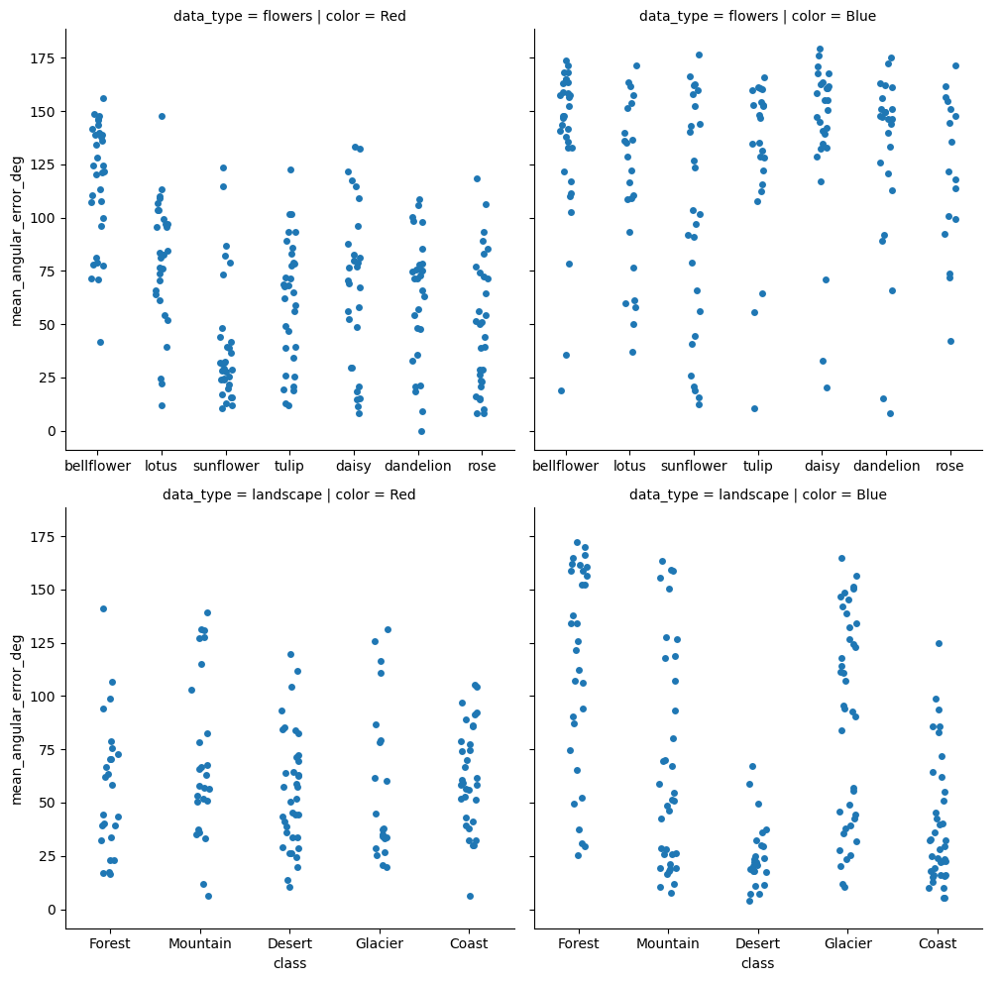

In [ ]:
g = sns.catplot(y='mean_angular_error_deg',x="class",col='color',row='data_type',
              data=results_df,sharex=False,kind="strip")
plt.tight_layout()

In [ ]:
high_error_images = results_df[((results_df['mean_angular_error_deg'] < 95)&(results_df['mean_angular_error_deg'] > 85)) | (results_df['mean_angular_error_deg'] > 175)]

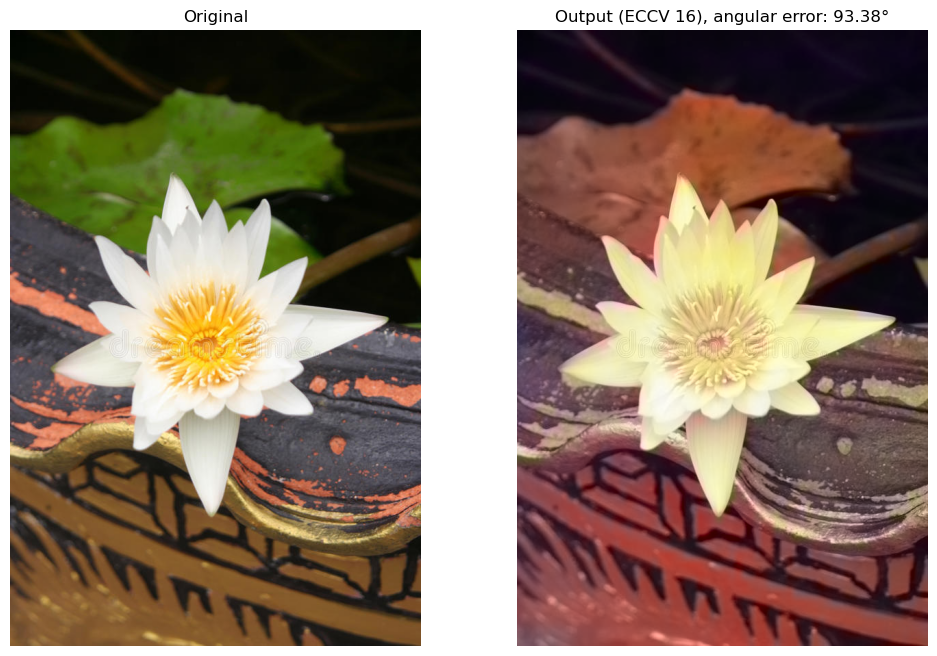

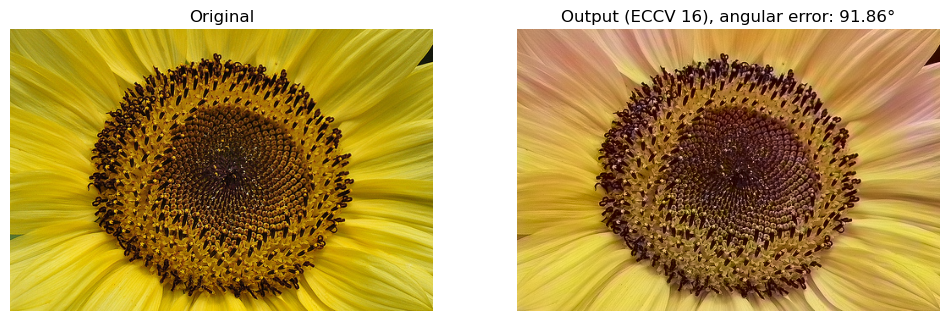

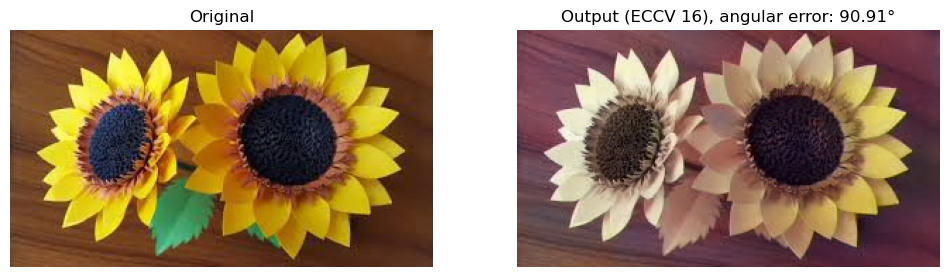

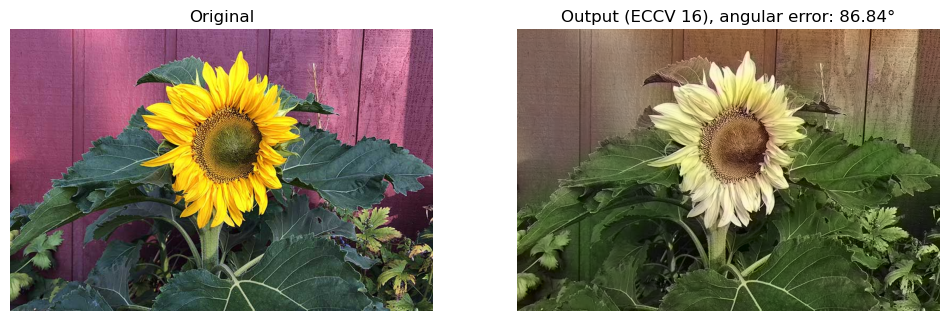

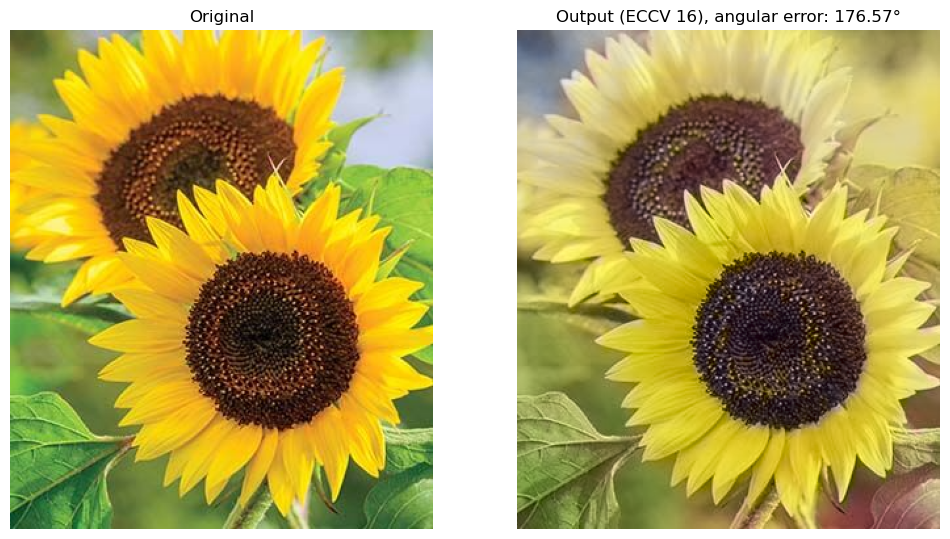

...

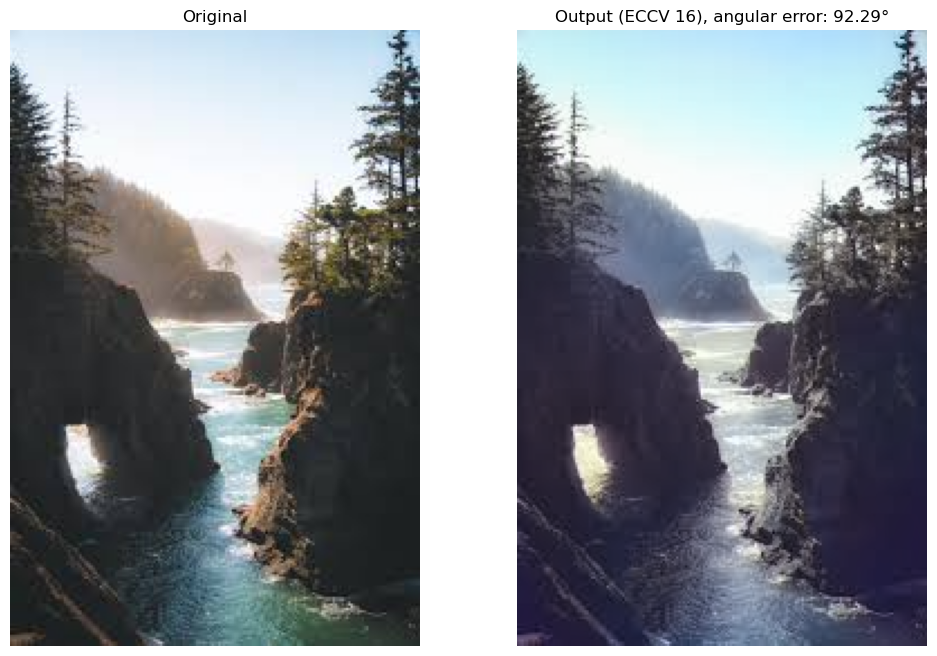

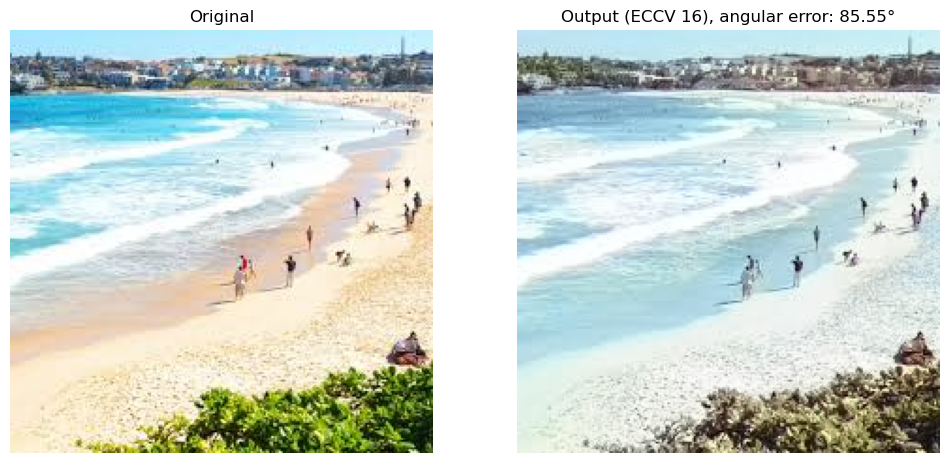

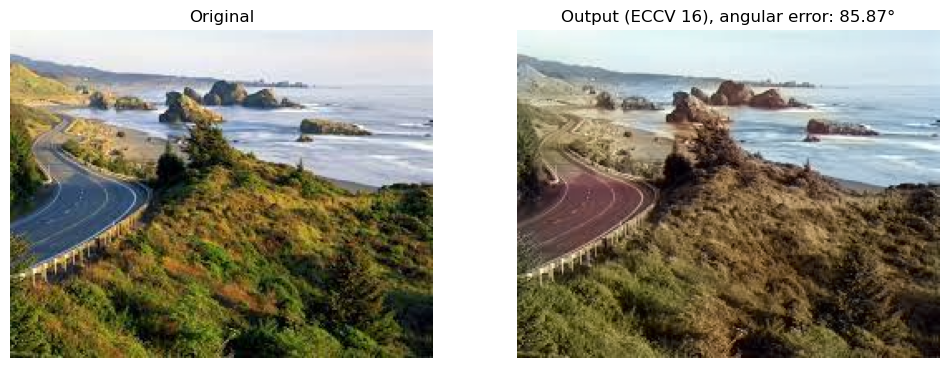

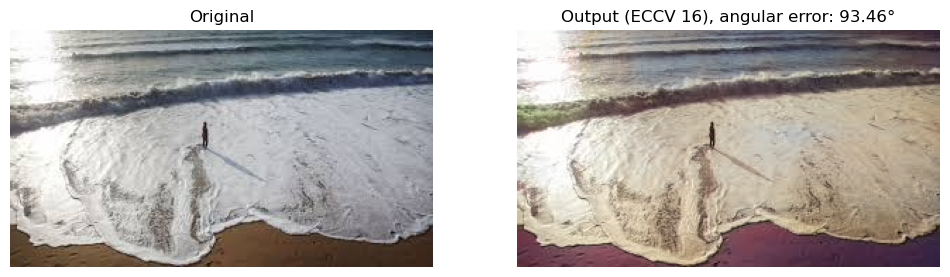

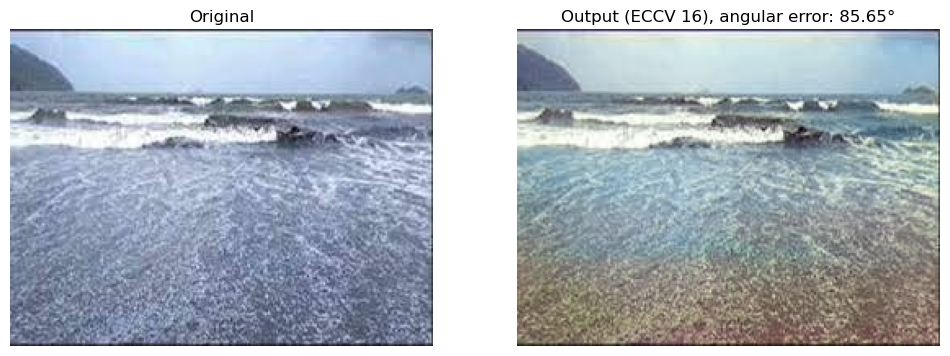

In [ ]:
for iimg in high_error_images['img_name'].values:
    itype = high_error_images[high_error_images['img_name']==iimg]['data_type'].values[0]
    iclass = high_error_images[high_error_images['img_name']==iimg]['class'].values[0]
    img_path = os.path.join(data_directory, itype, iclass, iimg)
    img = load_img(img_path)
    (tens_l_orig, tens_l_rs) = preprocess_img(img, HW=(256,256))
    if(opt.use_gpu):
        tens_l_rs = tens_l_rs.cuda()
    
    out_img_eccv16 = postprocess_tens(tens_l_orig, colorizer_eccv16(tens_l_rs).cpu())
    # out_img_siggraph17 = postprocess_tens(tens_l_orig, colorizer_siggraph17(tens_l_rs).cpu())

    plt.figure(figsize=(12,8))
    plt.subplot(1,2,1)
    plt.imshow(img)
    plt.title('Original')
    plt.axis('off')

    plt.subplot(1,2,2)
    plt.imshow(out_img_eccv16)
    plt.title('Output (ECCV 16), angular error: %.2f°'%high_error_images[high_error_images['img_name']==iimg]['mean_angular_error_deg'].values[0])
    plt.axis('off')
    plt.show()

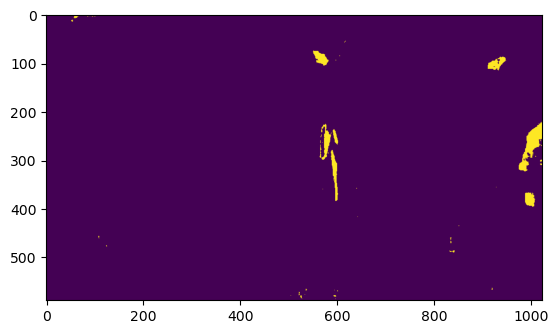

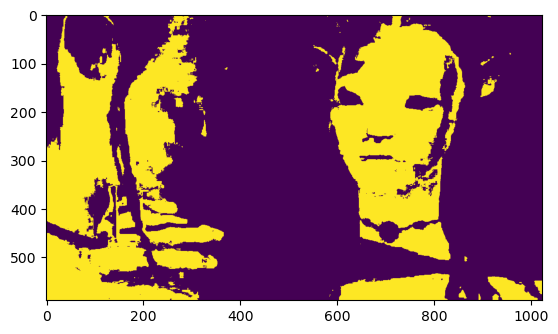

In [ ]:
plt.imshow(metrics['Red']['mask'])
plt.show()#
plt.imshow(metrics['Blue']['mask'])

In [ ]:
metrics.items()

dict_items([('Red', {'mean_delta_E': np.float64(8.58590271641118), 'mean_angular_error_deg': np.float64(7.3171107680275975), 'pixel_count': np.int64(48732)}), ('Blue', {'mean_delta_E': None, 'mean_angular_error_deg': None})])

In [ ]:
ground_truth = img
prediction = out_img_eccv16
    
metrics = evaluate_red_blue_performance(ground_truth, prediction)

for color, data in metrics.items():
    print(f"--- {color} Target Regions ---")
    print(f"Evaluated Pixels: {data['pixel_count']}")
    print(f"Mean Perceptual Distance (Delta E): {data['mean_delta_E']:.2f}")
    print(f"Mean Hue Angular Error: {data['mean_angular_error_deg']:.2f}°")

--- Red Target Regions ---
Evaluated Pixels: 1493
Mean Perceptual Distance (Delta E): 34.57
Mean Hue Angular Error: 41.23°
--- Blue Target Regions ---
Evaluated Pixels: 88944
Mean Perceptual Distance (Delta E): 50.04
Mean Hue Angular Error: 154.99°


In [ ]:
'''suffering from red/blue confusion: - we could still take ImmageNet for training

Unmarked/Everyday Clothing: A grayscale shirt can be logically red, blue, or brown. If the network lacks contextual clues (like a uniform or logo), it will frequently guess based on spatial probability, swapping red and blue.
Camouflaged or Low-Contrast Textures: When color values in the original grayscale image are ambiguous (similar luminance values), models can misread surface textures and assign the wrong hue channel.
Unusual or Rare Objects: A network trained on a standard dataset (e.g., ImageNet) knows that a strawberry is red. But for rare objects, abstract art, or unusual vehicles, it may default to a highly probable but incorrect color.
Vehicles (Cars/Bicycles): Grayscale cars are ubiquitous and can be produced in almost any color. Models often struggle with non-distinct cars and may arbitrarily color a vintage car red instead of blue.
Flowers & Man-Made Items: Bright flowers and household goods lack a strict "semantic" rule. In these instances, networks may guess complementary colors improperly, leading to red-blue confusion across petals or borders
'''

In [ ]:
'''Mean Angular Error close to 0∘: The model is predicting the correct hue direction perfectly.

    Mean Angular Error approaching 90∘ to 180∘: If your Red target regions show an angular error near 90∘ or higher, your model is heavily shifting those pixels toward the blue/yellow axes, indicating an active color confusion bug.

    Delta E (ΔE): A ΔE value of roughly 1.0 is the smallest color difference the human eye can perceive. For a generative colorization model, a ΔE under 5.0 to 10.0 in targeted chroma zones indicates solid performance. If it spikes drastically higher in your Red/Blue masks compared to other colors, your network lacks robustness on those specific wavelengths.'''

In [ ]:
'''go with flowers for new training dataset?'''

In [ ]:
'''how to adjust angular error to also capture splotching and object color bleed:

Splotching (Spatial Inconsistency)	Instead of averaging the error, calculate the Standard Deviation or Variance of the angular error within structurally continuous segments (like a single object). High variance inside a single object means splotching.
Object Color Bleed	Calculate the angular error specifically within a 5 to 10-pixel dilation band around your object segmentation boundaries. A spike in error right outside the boundary indicates bleeding.
Structural Alignment	Compare the spatial gradients (edges) of your angular error map to the edges of the original grayscale input. If the error map ignores the grayscale boundaries, color bleed is occurring.

or use Structural Similarity (SSIM) computed specifically on the chrominance channels'''

'how to adjust angular error to also capture splotching and object color bleed:\n\nSplotching (Spatial Inconsistency)\tInstead of averaging the error, calculate the Standard Deviation or Variance of the angular error within structurally continuous segments (like a single object). High variance inside a single object means splotching.\nObject Color Bleed\tCalculate the angular error specifically within a 5 to 10-pixel dilation band around your object segmentation boundaries. A spike in error right outside the boundary indicates bleeding.\nStructural Alignment\tCompare the spatial gradients (edges) of your angular error map to the edges of the original grayscale input. If the error map ignores the grayscale boundaries, color bleed is occurring.'

In [ ]:
color variance within segments

In [ ]:
'''model1–model4	Low/mid-level features (edges, textures, basic luminance)	✅ Freeze: These are general-purpose visual features already well-learned by the pretrained weights. Red/blue confusion is not a low-level feature problem.
model5–model6	Dilated context blocks (512 ch)	🔓 Unfreeze: Capture broader spatial context. Needed to help attention understand color relationships across the image.
model7	Pre-decoder bridge	🔓 Unfreeze: Translates context into decoder-ready features.
model8 + model_out	Decoder + 1×1 color mapping (313→2)	🔓 Unfreeze: This is where red/blue confusion lives. The network must learn to map luminance/texture to chrominance (a, b channels).'''

In [ ]:
from skimage.color import rgb2lab, deltaE_cie76

def evaluate_red_blue_performance(gt_rgb, pred_rgb, saturation_threshold=20):
    """
    Evaluates CNN colorization performance specifically for red and blue regions.
    
    gt_rgb: Ground truth image (NumPy array, HxWx3, uint8 or float 0-1)
    pred_rgb: Model's colorized output (NumPy array, HxWx3, uint8 or float 0-1)
    saturation_threshold: Minimum distance from origin in ab space to count as a strong color
    """
    # Convert both images to CIELAB space
    gt_lab = rgb2lab(gt_rgb)
    pred_lab = rgb2lab(pred_rgb)
    
    # Extract a* and b* channels
    gt_a, gt_b = gt_lab[..., 1], gt_lab[..., 2]
    pred_a, pred_b = pred_lab[..., 1], pred_lab[..., 2]
    
    # Define masks for True Red and True Blue in the Ground Truth
    # Red: High positive a*, low/neutral b*
    # Blue: High negative b*, low/neutral a*
    is_red = (gt_a > saturation_threshold) & (gt_a > np.abs(gt_b))
    is_blue = (gt_b < -saturation_threshold) & (-gt_b > np.abs(gt_a))
    
    results = {}
    
    for color_name, mask in [('Red', is_red), ('Blue', is_blue)]:
        if not np.any(mask):
            results[color_name] = {"mean_delta_E": None, "mean_angular_error_deg": None, "pixel_count": 0}
            continue
            
        # 1. Perceptual Color Distance (Delta E CIE76) specifically in masked regions
        de = deltaE_cie76(gt_lab, pred_lab)
        mean_de = np.mean(de[mask])
        
        # 2. Angular Error in ab space (checks if hue direction is swapped/confused)
        gt_vectors = np.stack([gt_a[mask], gt_b[mask]], axis=-1)
        pred_vectors = np.stack([pred_a[mask], pred_b[mask]], axis=-1)
        
        # Normalize vectors to unit length
        gt_norm = gt_vectors / np.linalg.norm(gt_vectors, axis=-1, keepdims=True)
        pred_norm = pred_vectors / np.linalg.norm(pred_vectors, axis=-1, keepdims=True)
        
        # Dot product to find cosine similarity
        dot_product = np.sum(gt_norm * pred_norm, axis=-1)
        dot_product = np.clip(dot_product, -1.0, 1.0) # Avoid numerical floating point errors
        
        # Calculate angles in degrees
        angles = np.degrees(np.arccos(dot_product))
        mean_angle = np.mean(angles)
        
        results[color_name] = {
            "mean_delta_E": mean_de,
            "mean_angular_error_deg": mean_angle,
            "pixel_count": np.sum(mask)#, "mask": mask
        }
        
    return results
# --- Example Usage ---
# if __name__ == "__main__":
#     Dummy images (HxWx3)
#     np.random.seed(42)
#     ground_truth = np.random.randint(0, 256, (256, 256, 3), dtype=np.uint8)
#     Simulate a model prediction
#     prediction = np.random.randint(0, 256, (256, 256, 3), dtype=np.uint8)

ground_truth = img
prediction = out_img_siggraph17
    
metrics = evaluate_red_blue_performance(ground_truth, prediction, saturation_threshold=10)

for color, data in metrics.items():
    print(f"--- {color} Target Regions ---")
    print(f"Evaluated Pixels: {data['pixel_count']}")
    print(f"Mean Perceptual Distance (Delta E): {data['mean_delta_E']:.2f}")
    print(f"Mean Hue Angular Error: {data['mean_angular_error_deg']:.2f}°")

# TODO how fast is this without masks?